In [2]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ ---------


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Load feature-engineered dataset
df = pd.read_csv("../data/processed/feature_engineered_sales.csv")

# Convert date column
df['date'] = pd.to_datetime(df['date'])

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,date,store,item,sales,year,month,day,day_of_week,week_of_year,is_weekend,lag_1,lag_7,rolling_mean_7
0,2013-01-08,1,1,9,2013,1,8,1,2,0,10.0,13.0,11.857143
1,2013-01-09,1,1,12,2013,1,9,2,2,0,9.0,11.0,11.285714
2,2013-01-10,1,1,9,2013,1,10,3,2,0,12.0,14.0,11.428571
3,2013-01-11,1,1,9,2013,1,11,4,2,0,9.0,13.0,10.714286
4,2013-01-12,1,1,7,2013,1,12,5,2,1,9.0,10.0,10.142857


In [5]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check date range
print("\nDate Range:")
print("Start Date:", df['date'].min())
print("End Date:", df['date'].max())

# Check columns
print("\nAvailable Features:")
print(df.columns.tolist())

Dataset Shape: (909500, 13)

Date Range:
Start Date: 2013-01-08 00:00:00
End Date: 2017-12-31 00:00:00

Available Features:
['date', 'store', 'item', 'sales', 'year', 'month', 'day', 'day_of_week', 'week_of_year', 'is_weekend', 'lag_1', 'lag_7', 'rolling_mean_7']


In [6]:
# Define the cutoff date
split_date = '2017-01-01'

# Split dataset chronologically
train_df = df[df['date'] < split_date].copy()
test_df = df[df['date'] >= split_date].copy()

# Display split information
print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

print("\nTraining Date Range:")
print(train_df['date'].min(), "to", train_df['date'].max())

print("\nTesting Date Range:")
print(test_df['date'].min(), "to", test_df['date'].max())

Training Dataset Shape: (727000, 13)
Testing Dataset Shape: (182500, 13)

Training Date Range:
2013-01-08 00:00:00 to 2016-12-31 00:00:00

Testing Date Range:
2017-01-01 00:00:00 to 2017-12-31 00:00:00


In [7]:
# Baseline Model: Use previous 7-day sales as prediction

y_test = test_df['sales']

baseline_predictions = test_df['lag_7']

# Calculate evaluation metrics
baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("Baseline Model Results")
print("----------------------")
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))

Baseline Model Results
----------------------
MAE: 8.8415
RMSE: 11.5967


In [8]:
# Select input features for the model

features = [
    'store',
    'item',
    'year',
    'month',
    'day',
    'day_of_week',
    'week_of_year',
    'is_weekend',
    'lag_1',
    'lag_7',
    'rolling_mean_7'
]

# Create training and testing feature sets
X_train = train_df[features]
X_test = test_df[features]

# Target variable
y_train = train_df['sales']
y_test = test_df['sales']

print("Features prepared successfully!")

print("\nTraining Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

Features prepared successfully!

Training Features Shape: (727000, 11)
Testing Features Shape: (182500, 11)


In [9]:
# Initialize Random Forest Regressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train the model
print("Training Random Forest Model...")

rf_model.fit(X_train, y_train)

print("Random Forest Model trained successfully!")

Training Random Forest Model...
Random Forest Model trained successfully!


In [11]:
# Check which training and testing variables exist
print("Available variables:")

for name in ['x_train', 'X_train', 'x_test', 'X_test',
             'y_train', 'Y_train', 'y_test', 'Y_test',
             'x_val', 'X_val', 'y_val', 'Y_val']:
    if name in globals():
        print(name, "exists")

Available variables:
X_train exists
X_test exists
y_train exists
y_test exists


In [14]:
# Generate predictions on validation data
rf_predictions = rf_model.predict(X_test)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

# Display results
print("Random Forest Model Results")
print("----------------------------")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))

Random Forest Model Results
----------------------------
MAE: 6.5211
RMSE: 8.5137


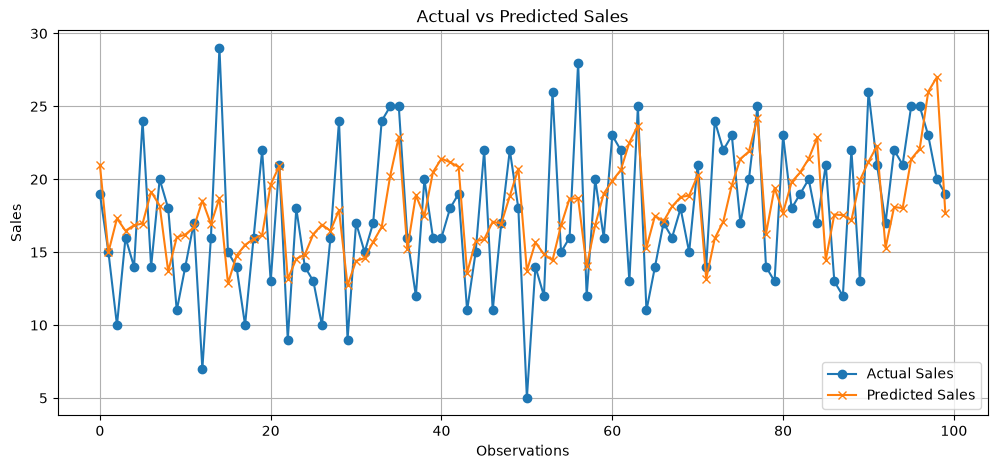

In [15]:
# Compare actual and predicted sales

plt.figure(figsize=(12, 5))

# Plot first 100 observations
plt.plot(
    y_test[:100].values,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    rf_predictions[:100],
    label="Predicted Sales",
    marker="x"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Observations")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.show()

Feature Importance:
           Feature  Importance
10  rolling_mean_7    0.745611
9            lag_7    0.204685
5      day_of_week    0.022204
8            lag_1    0.020901
4              day    0.001972
3            month    0.001543
6     week_of_year    0.001176
7       is_weekend    0.001090
1             item    0.000421
0            store    0.000244
2             year    0.000153


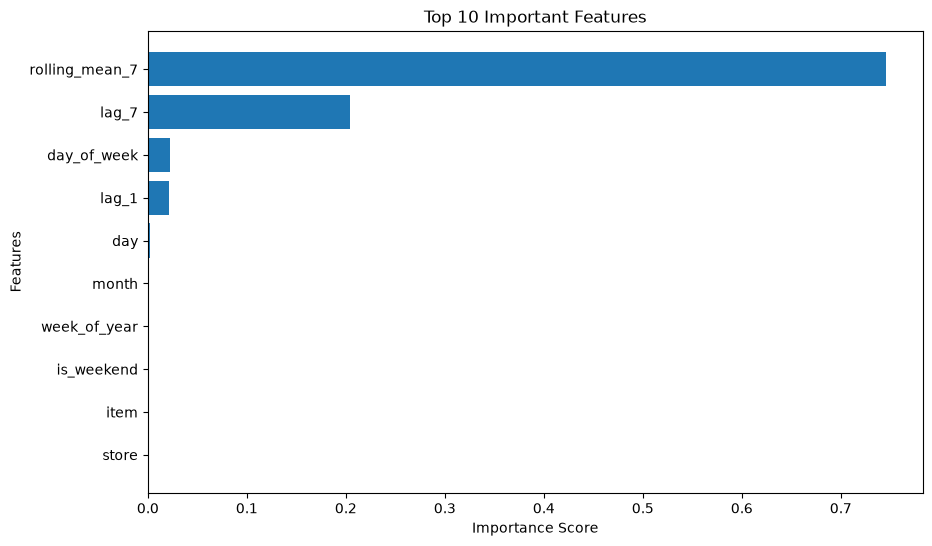

In [16]:
# Calculate feature importance

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
print(feature_importance)

# Visualize top 10 features
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'].head(10),
    feature_importance['Importance'].head(10)
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 10 Important Features")

plt.gca().invert_yaxis()
plt.show()

In [17]:
# Import joblib
import joblib
import os

# Create models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save trained Random Forest model
joblib.dump(
    rf_model,
    "../models/random_forest_model.pkl"
)

print("Random Forest model saved successfully!")
print("Location: models/random_forest_model.pkl")

Random Forest model saved successfully!
Location: models/random_forest_model.pkl


In [18]:
# Create outputs directory
os.makedirs("../outputs", exist_ok=True)

# Save model comparison results
results = pd.DataFrame({
    "Model": ["Baseline", "Random Forest"],
    "MAE": [baseline_mae, rf_mae],
    "RMSE": [baseline_rmse, rf_rmse]
})

results.to_csv(
    "../outputs/model_comparison.csv",
    index=False
)

# Save feature importance
feature_importance.to_csv(
    "../outputs/feature_importance.csv",
    index=False
)

print("Evaluation results saved successfully!")
print(results)

Evaluation results saved successfully!
           Model       MAE       RMSE
0       Baseline  8.841452  11.596704
1  Random Forest  6.521124   8.513704
